Compute correlation between the principal FC gradient-based hierarchy and the T1w:T2w-based cortical hierarchy

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import pearsonr, zscore
import scienceplots
plt.style.use(['science', 'nature'])
import seaborn as sns
from matplotlib.colors import ListedColormap
colors = {
    "grey":   "#4d4d4d", # neutral line/axis color
}
import matplotlib as mpl
mpl.rcParams.update({
    "font.size": 7,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
})

FC grad vs. hierarchy:  Pearson r = 0.593, p_spin = 0.0004  |  (N = 50 parcels, 10000 spins)


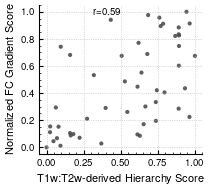

In [2]:
import numpy as np
import pandas as pd
from neuromaps.nulls import hungarian
from neuromaps.stats import compare_images
from neuromaps.images import annot_to_gifti

x_full = np.asarray(pd.read_csv('../../data/processed/schaefer100_LH_hierarchy.csv')['Hierarchy_val'], dtype=float)  # hierarchy, no NaN
hier_fc_grad_full = np.asarray(pd.read_csv('../../data/processed/schaefer100_LH_FC_grad_hierarchy.csv')['FC_hierarchy_val'], dtype=float)
assert x_full.size == 50

# The .annot labels are ordered [medial wall, Vis_1, Vis_2, ...]
# 1..50 match the ordering of the receptor / hierarchy vectors above.
_lh_annot = ('../../data/raw/brain_annotations/Schaefer/fsaverage/'
             'atl-Schaefer2018_space-fsaverage_hemi-L_'
             'desc-100Parcels7Networks_deterministic.annot')
_parc = annot_to_gifti((_lh_annot,))

# generate spins from the hierarchy map
# hungarian projects the parcel centroids onto the fsaverage sphere
# and applies N_PERM random rotations
N_PERM = 10000
spins = hungarian(x_full, atlas='fsaverage', density='164k',
                  parcellation=_parc, n_perm=N_PERM, seed=1234)

def spin_test(y_full, metric='pearsonr'):
    """nan_policy='omit' drops the parcels without autorad data. Returns the
    observed r, the spin p-value, and the null distribution of r values."""
    r, p, null = compare_images(x_full, y_full, metric=metric, nulls=spins,
                                nan_policy='omit', ignore_zero=False,
                                return_nulls=True)
    return r, p, np.asarray(null).ravel()

def print_spin_null(name, y_full):
    r_p, p_p, null_p = spin_test(y_full, metric='pearsonr')
    n_used = int(np.sum(~np.isnan(y_full)))
    print(f'{name}:  Pearson r = {r_p:.3f}, p_spin = {p_p:.4f}  |  '
          f'(N = {n_used} parcels, {N_PERM} spins)')
    return r_p, p_p

r, p = print_spin_null('FC grad vs. hierarchy', hier_fc_grad_full)

fig, ax = plt.subplots(figsize=(2.2, 2.0))
ax.scatter(x_full, hier_fc_grad_full, s=9, alpha=0.9, color=colors['grey'], edgecolor='none')
ax.set_xlabel('T1w:T2w-derived Hierarchy Score')
ax.set_ylabel('Normalized FC Gradient Score')
ax.grid(linestyle=':', alpha=0.9)
ax = plt.gca()
for spine in ['top','right']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
ax.tick_params(axis='both', which='major')
ax.tick_params(axis='both', which='minor')
ax.text(
    0.5, 0.98, f"r={r:.2f}",
    transform=ax.transAxes,
    va="top",
    ha="right"
)
plt.tight_layout()
plt.savefig('plots/FC_grad/FC_hier_vs_t1t1hier.svg', bbox_inches='tight')
plt.show()

In [3]:
print_spin_null('FC grad vs. hierarchy', hier_fc_grad_full)

FC grad vs. hierarchy:  Pearson r = 0.593, p_spin = 0.0004  |  (N = 50 parcels, 10000 spins)


(np.float64(0.5926436711505819), np.float64(0.00039996000399960006))

## Journal-format version of the FC gradient vs. T1w:T2w hierarchy panel

Same plot as above, restyled to match the assembled panels of `../Figure_1.ipynb` / `../Figure_2.ipynb`:
all text at **8 pt Open Sans**, editable text in the SVG/PDF, and the same axis / tick line widths.

The figure is the full double-column width used in Figure 1 (18.3 cm) but only 5 cm tall.
A half-width (9.15 cm x 5 cm) variant is written out as well, in case the panel should occupy
only half of the row.

This cell reuses `x_full`, `hier_fc_grad_full` and the spin-test result (`r`, `p`) computed above,
so run the previous cells first. Nothing above is modified: the styling is applied only inside
the `mpl.rc_context` block.

FC_hier_vs_t1t1hier_journal_fullwidth: 18.30 x 5.00 cm (r = 0.593, p_spin = 0.0004)


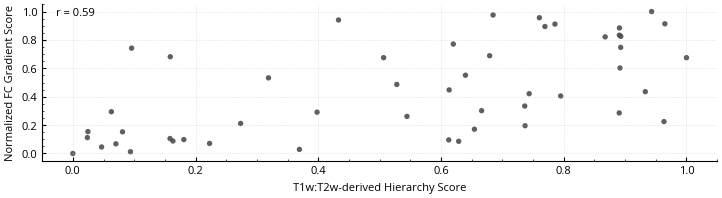

FC_hier_vs_t1t1hier_journal_halfwidth: 9.15 x 5.00 cm (r = 0.593, p_spin = 0.0004)


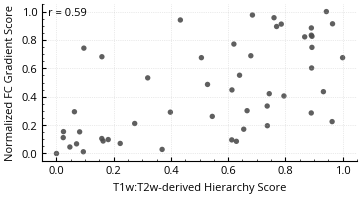

In [4]:
# Journal-ready version of the FC gradient vs. T1w:T2w hierarchy scatter.
# Full double-column width (18.3 cm, as in Figure_1), height 5 cm, all text at 8 pt Open Sans.
import os
import matplotlib as mpl

# Identical to the rc_context used in the assembly cell of ../Figure_1.ipynb.
# Applied only inside the "with" block below, so the earlier cells are unaffected.
# Note: the 'science' style sets text.usetex = True, and LaTeX ignores font.family,
# so usetex has to be off for Open Sans to actually be used.
fig_params = {
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Open Sans"],
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.title_fontsize": 8,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "pdf.fonttype": 42,   # keep text as editable text, not outlines
    "ps.fonttype": 42,
    "svg.fonttype": "none",
}

CM = 1 / 2.54
FULL_WIDTH_CM = 18.3   # double-column width used in Figure_1
HEIGHT_CM = 5.0        # requested height

OUT_DIR = 'plots/FC_grad'
os.makedirs(OUT_DIR, exist_ok=True)


def plot_fc_vs_hierarchy(width_cm, out_name, height_cm=HEIGHT_CM):
    """Draw the scatter at an exact physical size and save it as SVG + PDF.

    No bbox_inches='tight' on save, so the file keeps exactly width_cm x height_cm.
    """
    with mpl.rc_context(fig_params):
        fig, ax = plt.subplots(figsize=(width_cm * CM, height_cm * CM),
                               constrained_layout=True)

        ax.scatter(x_full, hier_fc_grad_full, s=15, alpha=0.9,
                   color=colors['grey'], edgecolor='none')

        ax.set_xlabel('T1w:T2w-derived Hierarchy Score')
        ax.set_ylabel('Normalized FC Gradient Score')
        ax.grid(linestyle=':', alpha=0.5)
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)
        ax.xaxis.set_ticks_position('bottom')
        ax.yaxis.set_ticks_position('left')

        # Top-left corner: the correlation is positive, so that corner is always empty.
        # (In Figure_1 the r value sits top-right, but here a data point is in the way.)
        ax.text(0.02, 0.98, f'r = {r:.2f}', transform=ax.transAxes,
                va='top', ha='left')

        fig.savefig(f'{OUT_DIR}/{out_name}.svg')
        fig.savefig(f'{OUT_DIR}/{out_name}.pdf')
        print(f'{out_name}: {width_cm:.2f} x {height_cm:.2f} cm '
              f'(r = {r:.3f}, p_spin = {p:.4f})')
        plt.show()


# Full-width panel (18.3 x 5 cm)
plot_fc_vs_hierarchy(FULL_WIDTH_CM, 'FC_hier_vs_t1t1hier_journal_fullwidth')

# Half-width panel (9.15 x 5 cm), same 8 pt text
plot_fc_vs_hierarchy(FULL_WIDTH_CM / 2, 'FC_hier_vs_t1t1hier_journal_halfwidth')